# PSF-only单星stamp质心偏差验证

本notebook验证星点中心落在同一中心像素的不同7×7亚像素位置时，一阶灰度质心相对真值质心的系统偏差。仿真只保留PSF信号，不加入光子噪声、读出噪声、暗电流、背景、PRNU、抖动或ADC随机项。

- 凌星导星PSF链路参考：`/home/liyang/ET7/ET-fsgsim/scripts/et_sim_guide_det_v1_noise_psf.py`
- 微引力导星PSF链路参考：`/home/liyang/ET7/ET-fsgsim/scripts/et_sim_microlens_guide_det_v1_noise_psf.py`
- 质心公式参考：`/home/liyang/ET7/ET-fsglib/fsglib/extract/pipeline.py`中的`_first_moment_in_bbox`

坐标约定：stamp局部像素坐标从0到30，中心像素中心为$(15,15)$。

In [9]:
from __future__ import annotations

import json
import math
import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy import units as u
from IPython.display import display
from scipy.interpolate import RegularGridInterpolator

PHOTSIM_ROOT = Path("/home/liyang/ET7/Photsim7")
PHOTSIM_DATA_DIR = Path("/home/liyang/ET7/Photsim7-data")
FSGSIM_ROOT = Path("/home/liyang/ET7/ET-fsgsim")
FSGLIB_ROOT = Path("/home/liyang/ET7/ET-fsglib")
OUTPUT_DIR = Path("/home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp")

STAMP_SIZE = 31
N_SUBPIXELS = 7
STAR_MAG_ET = 10.6
SATURATED_BRIGHT_MAG_ET = 10.2
SATURATION_LIMIT_ADU = 1800.0
GUIDE_EXPOSURE_S = 0.25
GAIN_E_PER_ADU = 0.45
ET_QE_CORRECTION = 0.91526
ET_SINGLE_SCOPE_ZEROPOINT_E_PER_S = 615.75 * 1_961_225

TRANSIT_BUNDLE_NAME = "241006/D280mm-focus-guide6p5um"
TRANSIT_FIELD_ID = 7
MICROLENS_BUNDLE_NAME = "microlens/RebinnedPSF_LE_BEST_GD1_Field1_multiband_Defocus0"
MICROLENS_FIELD_ID = 0

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ["ET_DATA_DIR"] = str(PHOTSIM_DATA_DIR)

print(f"Photsim7: {PHOTSIM_ROOT}")
print(f"Output:   {OUTPUT_DIR}")
print(f"stamp={STAMP_SIZE}x{STAMP_SIZE}, subpixels={N_SUBPIXELS}x{N_SUBPIXELS}, dark_ref_mag={STAR_MAG_ET}, saturated_mag={SATURATED_BRIGHT_MAG_ET}")

Photsim7: /home/liyang/ET7/Photsim7
Output:   /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp
stamp=31x31, subpixels=7x7, dark_ref_mag=10.6, saturated_mag=10.2


## 1. 配置路径、参数与依赖库

上一个代码单元设置了Photsim7、ET-fsgsim、ET-fsglib路径，以及31×31 stamp、7×7亚像素、10.6等星和1800 ADU非饱和阈值。当前kernel固定使用`py311`。

## 2. 加载并复用凌星导星与微引力导星仿真链路

这里不跑完整星场仿真，而是复用Photsim7的PSF bundle加载与`PSFModelManager`局部网格采样路径。这样可以只保留PSF信号，关闭所有噪声、背景、暗电流、PRNU和抖动。

In [10]:
def install_numpy_pickle_aliases() -> None:
    """Allow py311/NumPy 1.24 to load PSF pickles written by NumPy 2.x."""
    numpy_core_aliases = {
        "numpy._core": np.core,
        "numpy._core.multiarray": np.core.multiarray,
        "numpy._core.numeric": np.core.numeric,
        "numpy._core.numerictypes": np.core.numerictypes,
        "numpy._core.umath": np.core.umath,
    }
    if hasattr(np.core, "_multiarray_umath"):
        numpy_core_aliases["numpy._core._multiarray_umath"] = np.core._multiarray_umath
    for alias, module in numpy_core_aliases.items():
        sys.modules.setdefault(alias, module)


def et_mag_to_electrons(mag: float, exposure_s: float) -> float:
    photon_rate = ET_QE_CORRECTION * ET_SINGLE_SCOPE_ZEROPOINT_E_PER_S * 10 ** (-0.4 * float(mag))
    return float(photon_rate * float(exposure_s))


def mag_for_target_peak(reference_mag: float, reference_peak_adu: float, target_peak_adu: float) -> float:
    if reference_peak_adu <= 0:
        raise ValueError("reference_peak_adu must be positive")
    return float(reference_mag - 2.5 * math.log10(float(target_peak_adu) / float(reference_peak_adu)))


def subpixel_absolute_grid(stamp_size: int = STAMP_SIZE, n_subpixels: int = N_SUBPIXELS):
    subpixel_center_offset = (int(n_subpixels) - 1) / 2.0
    coords = (np.arange(int(stamp_size) * int(n_subpixels), dtype=np.float64) - subpixel_center_offset) / int(n_subpixels)
    return np.meshgrid(coords, coords)


def downsample_subpixel_image(subpixel_image: np.ndarray, n_subpixels: int = N_SUBPIXELS) -> np.ndarray:
    n_rows_sub, n_cols_sub = subpixel_image.shape
    return subpixel_image.reshape(
        n_rows_sub // n_subpixels,
        n_subpixels,
        n_cols_sub // n_subpixels,
        n_subpixels,
    ).sum(axis=(1, 3))


def load_psf_bundle_model(bundle_name: str, field_id: int, requested_subpixels: int = N_SUBPIXELS) -> dict:
    install_numpy_pickle_aliases()
    path = PHOTSIM_DATA_DIR / "psf" / "et" / bundle_name / "sim_psf_images.pkl"
    if not path.is_file():
        raise FileNotFoundError(f"Missing PSF bundle: {path}")

    with path.open("rb") as handle:
        bundle = pickle.load(handle)

    images_by_field = bundle["images"]
    image_entry = images_by_field[int(field_id)]
    if isinstance(image_entry, dict):
        available = sorted(int(key) for key in image_entry)
        selected_subpixels = requested_subpixels if requested_subpixels in image_entry else available[-1]
        model_image = np.asarray(image_entry[selected_subpixels], dtype=np.float64)
    else:
        selected_subpixels = requested_subpixels
        model_image = np.asarray(image_entry, dtype=np.float64)

    x_grid = model_image[0]
    y_grid = model_image[1]
    psf = np.clip(model_image[2], 0.0, None)
    if psf.sum() <= 0:
        raise ValueError(f"PSF model has non-positive flux: {bundle_name}, field {field_id}")
    psf = psf / psf.sum()

    x_coords = np.asarray(x_grid[0, :], dtype=np.float64)
    y_coords = np.asarray(y_grid[:, 0], dtype=np.float64)
    interpolator = RegularGridInterpolator(
        (y_coords, x_coords),
        psf,
        method="linear",
        bounds_error=False,
        fill_value=0.0,
    )
    return {
        "bundle_name": bundle_name,
        "field_id": int(field_id),
        "path": path,
        "selected_subpixels": int(selected_subpixels),
        "x_range": (float(x_coords.min()), float(x_coords.max())),
        "y_range": (float(y_coords.min()), float(y_coords.max())),
        "interpolator": interpolator,
    }


def render_psf_only_signal_adu(model: dict, x_true: float, y_true: float, photon_count_e: float) -> np.ndarray:
    abs_x_sub, abs_y_sub = subpixel_absolute_grid()
    rel_x_sub = abs_x_sub - float(x_true)
    rel_y_sub = abs_y_sub - float(y_true)
    sample_points = np.column_stack([rel_y_sub.ravel(), rel_x_sub.ravel()])
    psf_sub = np.asarray(model["interpolator"](sample_points), dtype=np.float64).reshape(rel_x_sub.shape)
    psf_sub = np.clip(psf_sub, 0.0, None)
    sample_sum = float(psf_sub.sum())
    if sample_sum <= 0.0 or not np.isfinite(sample_sum):
        raise ValueError(f"Local PSF sample has invalid flux for {model['bundle_name']}")
    psf_sub = psf_sub / sample_sum * float(photon_count_e)
    stamp_e = downsample_subpixel_image(psf_sub)
    return stamp_e / GAIN_E_PER_ADU


def apply_detector_adc(signal_adu: np.ndarray, *, full_well_adu: float, bias_adu: float, adc_max_adu: float, round_values: bool = True):
    clipped_signal = np.minimum(np.asarray(signal_adu, dtype=np.float64), float(full_well_adu))
    raw_adu = np.clip(clipped_signal + float(bias_adu), 0.0, float(adc_max_adu))
    if round_values:
        raw_adu = np.rint(raw_adu)
    calibrated_signal = np.clip(raw_adu - float(bias_adu), 0.0, None)
    return raw_adu, calibrated_signal


def first_moment_centroid(stamp: np.ndarray) -> tuple[float, float, float]:
    image = np.asarray(stamp, dtype=np.float64)
    yy, xx = np.indices(image.shape, dtype=np.float64)
    flux = float(image.sum())
    if flux <= 0.0 or not np.isfinite(flux):
        return np.nan, np.nan, flux
    x_c = float((xx * image).sum() / flux)
    y_c = float((yy * image).sum() / flux)
    return x_c, y_c, flux


photon_count_e_025s = et_mag_to_electrons(STAR_MAG_ET, GUIDE_EXPOSURE_S)
print(f"10.6 ET mag at {GUIDE_EXPOSURE_S:.3f}s -> {photon_count_e_025s:.2f} e-, {photon_count_e_025s / GAIN_E_PER_ADU:.2f} ADU total")

10.6 ET mag at 0.250s -> 15900.70 e-, 35334.90 ADU total


## 3. 定义31×31单星stamp与7×7亚像素落点

中心像素坐标为$(15,15)$。7×7亚像素中心相对像素中心的可取偏移为$[-3,-2,-1,0,1,2,3]/7$ pixel。本验证选取三个位置：

- `pixel_center`：$(0,0)$
- `edge_subpixel`：中心像素右边缘方向的亚像素中心，$(3/7,0)$
- `corner_subpixel`：中心像素右上角方向的角落亚像素中心，$(3/7,3/7)$

In [11]:
CENTER_PIX = (STAMP_SIZE - 1) / 2.0
PHASES = [
    {"phase_label": "pixel_center", "dx_pix": 0.0, "dy_pix": 0.0},
    {"phase_label": "edge_subpixel", "dx_pix": 3.0 / N_SUBPIXELS, "dy_pix": 0.0},
    {"phase_label": "corner_subpixel", "dx_pix": 3.0 / N_SUBPIXELS, "dy_pix": 3.0 / N_SUBPIXELS},
]
DETECTOR_SPECS = [
    {
        "detector": "transit_guide",
        "bundle_name": TRANSIT_BUNDLE_NAME,
        "field_id": TRANSIT_FIELD_ID,
        "source_script": str(FSGSIM_ROOT / "scripts" / "et_sim_guide_det_v1_noise_psf.py"),
    },
    {
        "detector": "microlens_guide",
        "bundle_name": MICROLENS_BUNDLE_NAME,
        "field_id": MICROLENS_FIELD_ID,
        "source_script": str(FSGSIM_ROOT / "scripts" / "et_sim_microlens_guide_det_v1_noise_psf.py"),
    },
]

phase_table = pd.DataFrame(
    [
        {
            **phase,
            "x_true_pix": CENTER_PIX + phase["dx_pix"],
            "y_true_pix": CENTER_PIX + phase["dy_pix"],
        }
        for phase in PHASES
    ]
)
display(phase_table)

,phase_label,dx_pix,dy_pix,x_true_pix,y_true_pix
0,pixel_center,0.000000,0.000000,15.000000,15.000000
1,edge_subpixel,0.428571,0.000000,15.428571,15.000000
2,corner_subpixel,0.428571,0.428571,15.428571,15.428571


## 4. 生成无噪声PSF-only仿真星图

下面为两个探测器分别加载PSF模型，并在三个亚像素相位上渲染31×31 stamp。每个探测器、每个相位会生成两组星图：

- `non_saturated_dark`：自动选择一个不超过1800 ADU满阱的暗星星等。
- `saturated_bright`：固定使用10.2等亮星，并按满阱1800 ADU截断、加135 ADU偏置、12bit ADC量化。质心测量使用减去偏置后的信号图，因此偏差主要反映PSF形状、采样相位和饱和截断。

In [12]:
BIAS_ADU = 135.0
ADC_BIT_DEPTH = 12
ADC_MAX_ADU = float(2**ADC_BIT_DEPTH - 1)
NON_SAT_TARGET_PEAK_ADU = 0.90 * SATURATION_LIMIT_ADU


def bundle_path(bundle_name: str) -> Path:
    return PHOTSIM_DATA_DIR / "psf" / "et" / bundle_name / "sim_psf_images.pkl"


def load_detector_models() -> dict[str, dict]:
    models = {}
    for spec in DETECTOR_SPECS:
        print(f"Loading {spec['detector']} PSF: {bundle_path(spec['bundle_name'])}")
        model = load_psf_bundle_model(spec["bundle_name"], spec["field_id"], requested_subpixels=N_SUBPIXELS)
        print(
            f"  selected PSF subpixel layer={model['selected_subpixels']}, "
            f"x_range={model['x_range']}, y_range={model['y_range']}"
        )
        models[spec["detector"]] = model
    return models


def render_linear_psf_table(models: dict[str, dict], mag_et: float) -> tuple[pd.DataFrame, dict[str, np.ndarray]]:
    photon_count_e = et_mag_to_electrons(mag_et, GUIDE_EXPOSURE_S)
    rows = []
    signal_stamps = {}
    for spec in DETECTOR_SPECS:
        detector = spec["detector"]
        model = models[detector]
        for phase in PHASES:
            x_true = CENTER_PIX + phase["dx_pix"]
            y_true = CENTER_PIX + phase["dy_pix"]
            signal_adu = render_psf_only_signal_adu(model, x_true, y_true, photon_count_e)
            key = f"linear__{detector}__{phase['phase_label']}"
            signal_stamps[key] = signal_adu
            rows.append(
                {
                    "key": key,
                    "detector": detector,
                    "phase_label": phase["phase_label"],
                    "bundle_name": spec["bundle_name"],
                    "field_id": int(spec["field_id"]),
                    "psf_selected_subpixels": int(model["selected_subpixels"]),
                    "source_script": spec["source_script"],
                    "mag_et": float(mag_et),
                    "x_true_pix": float(x_true),
                    "y_true_pix": float(y_true),
                    "photon_count_e": float(photon_count_e),
                    "preclip_total_adu": float(signal_adu.sum()),
                    "preclip_peak_adu": float(signal_adu.max()),
                }
            )
    return pd.DataFrame(rows), signal_stamps


def choose_dark_magnitude(models: dict[str, dict]) -> tuple[float, pd.DataFrame]:
    trial_table, _ = render_linear_psf_table(models, STAR_MAG_ET)
    trial_peak = float(trial_table["preclip_peak_adu"].max())
    dark_mag = STAR_MAG_ET
    if trial_peak >= SATURATION_LIMIT_ADU:
        dark_mag = mag_for_target_peak(STAR_MAG_ET, trial_peak, NON_SAT_TARGET_PEAK_ADU)
    return float(dark_mag), trial_table


def build_scenario_stamps(models: dict[str, dict], scenario_name: str, mag_et: float, *, saturate: bool):
    linear_table, linear_stamps = render_linear_psf_table(models, mag_et)
    rows = []
    measurement_stamps = {}
    raw_stamps = {}
    preclip_stamps = {}

    for row in linear_table.to_dict("records"):
        linear_key = row["key"]
        key = f"{scenario_name}__{row['detector']}__{row['phase_label']}"
        preclip_signal = linear_stamps[linear_key]
        raw_adu, measured_signal = apply_detector_adc(
            preclip_signal,
            full_well_adu=SATURATION_LIMIT_ADU if saturate else 1.0e30,
            bias_adu=BIAS_ADU,
            adc_max_adu=ADC_MAX_ADU,
            round_values=True,
        )
        n_saturated_pixels = int(np.count_nonzero(preclip_signal > SATURATION_LIMIT_ADU))
        measurement_stamps[key] = measured_signal
        raw_stamps[key] = raw_adu
        preclip_stamps[key] = preclip_signal
        rows.append(
            {
                **{k: v for k, v in row.items() if k != "key"},
                "key": key,
                "scenario": scenario_name,
                "saturated_mode": bool(saturate),
                "bias_adu": BIAS_ADU,
                "adc_bit_depth": ADC_BIT_DEPTH,
                "adc_max_adu": ADC_MAX_ADU,
                "full_well_adu": SATURATION_LIMIT_ADU,
                "raw_peak_adu": float(raw_adu.max()),
                "measured_signal_peak_adu": float(measured_signal.max()),
                "measured_signal_total_adu": float(measured_signal.sum()),
                "n_saturated_pixels": n_saturated_pixels,
                "is_saturated": bool(n_saturated_pixels > 0),
            }
        )
    return pd.DataFrame(rows), measurement_stamps, raw_stamps, preclip_stamps


psf_models = load_detector_models()
dark_mag_et, trial_table_10p6 = choose_dark_magnitude(psf_models)
bright_mag_et = float(SATURATED_BRIGHT_MAG_ET)
bright_trial_table, _ = render_linear_psf_table(psf_models, bright_mag_et)
scenario_specs = [
    {"scenario": "non_saturated_dark", "mag_et": dark_mag_et, "saturate": False},
    {"scenario": "saturated_bright", "mag_et": bright_mag_et, "saturate": True},
]

scenario_tables = []
measurement_stamps = {}
raw_stamps = {}
preclip_stamps = {}
for scenario in scenario_specs:
    table, measured, raw, preclip = build_scenario_stamps(
        psf_models,
        scenario["scenario"],
        scenario["mag_et"],
        saturate=scenario["saturate"],
    )
    scenario_tables.append(table)
    measurement_stamps.update(measured)
    raw_stamps.update(raw)
    preclip_stamps.update(preclip)

stamp_table = pd.concat(scenario_tables, ignore_index=True)
print(f"10.6 trial max preclip peak = {trial_table_10p6['preclip_peak_adu'].max():.3f} ADU")
print(f"Dark non-saturated mag = {dark_mag_et:.4f}")
print(f"Fixed bright saturated mag = {bright_mag_et:.4f}")
print(f"10.2 bright-star preclip max peak = {bright_trial_table['preclip_peak_adu'].max():.3f} ADU")
print(f"Detector response for saturated case: full well={SATURATION_LIMIT_ADU:.1f} ADU, bias={BIAS_ADU:.1f} ADU, ADC={ADC_BIT_DEPTH} bit")
display(
    stamp_table[
        [
            "scenario",
            "detector",
            "phase_label",
            "mag_et",
            "psf_selected_subpixels",
            "preclip_peak_adu",
            "measured_signal_peak_adu",
            "raw_peak_adu",
            "n_saturated_pixels",
            "x_true_pix",
            "y_true_pix",
        ]
    ]
)

Loading transit_guide PSF: /home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-focus-guide6p5um/sim_psf_images.pkl
  selected PSF subpixel layer=7, x_range=(-12.428571701049805, 12.428571701049805), y_range=(-12.428571701049805, 12.428571701049805)
Loading microlens_guide PSF: /home/liyang/ET7/Photsim7-data/psf/et/microlens/RebinnedPSF_LE_BEST_GD1_Field1_multiband_Defocus0/sim_psf_images.pkl
  selected PSF subpixel layer=1, x_range=(-78.0, 78.0), y_range=(-78.0, 78.0)
10.6 trial max preclip peak = 3417.780 ADU
Dark non-saturated mag = 11.4106
Fixed bright saturated mag = 10.2000
10.2 bright-star preclip max peak = 4940.195 ADU
Detector response for saturated case: full well=1800.0 ADU, bias=135.0 ADU, ADC=12 bit


,scenario,detector,phase_label,mag_et,psf_selected_subpixels,preclip_peak_adu,measured_signal_peak_adu,raw_peak_adu,n_saturated_pixels,x_true_pix,y_true_pix
0,non_saturated_dark,transit_guide,pixel_center,11.410573,7,1586.186417,1586.0,1721.0,0,15.000000,15.000000
1,non_saturated_dark,transit_guide,edge_subpixel,11.410573,7,1605.460215,1605.0,1740.0,0,15.428571,15.000000
2,non_saturated_dark,transit_guide,corner_subpixel,11.410573,7,1620.000000,1620.0,1755.0,0,15.428571,15.428571
3,non_saturated_dark,microlens_guide,pixel_center,11.410573,1,1379.636205,1380.0,1515.0,0,15.000000,15.000000
4,non_saturated_dark,microlens_guide,edge_subpixel,11.410573,1,1220.921241,1221.0,1356.0,0,15.428571,15.000000
5,non_saturated_dark,microlens_guide,corner_subpixel,11.410573,1,1308.006604,1308.0,1443.0,0,15.428571,15.428571
6,saturated_bright,transit_guide,pixel_center,10.200000,7,4837.080664,1800.0,1935.0,6,15.000000,15.000000
7,saturated_bright,transit_guide,edge_subpixel,10.200000,7,4895.856175,1800.0,1935.0,5,15.428571,15.000000
8,saturated_bright,transit_guide,corner_subpixel,10.200000,7,4940.195296,1800.0,1935.0,6,15.428571,15.428571
9,saturated_bright,microlens_guide,pixel_center,10.200000,1,4207.205117,1800.0,1935.0,6,15.000000,15.000000


## 5. 输出真值质心、测量质心和残差表格

对每张stamp使用一阶灰度加权质心：$x_c=\frac{\sum x_i I_i}{\sum I_i}$，$y_c=\frac{\sum y_i I_i}{\sum I_i}$。这里的输入$I_i$为减去135 ADU偏置后的信号图；饱和亮星会保留满阱截断和12bit ADC量化的影响。

In [13]:
def centroid_shape_metrics(stamp: np.ndarray, x_c: float, y_c: float) -> dict[str, float]:
    image = np.asarray(stamp, dtype=np.float64)
    yy, xx = np.indices(image.shape, dtype=np.float64)
    flux = float(image.sum())
    dx = xx - x_c
    dy = yy - y_c
    mxx = float((image * dx * dx).sum() / flux)
    myy = float((image * dy * dy).sum() / flux)
    mxy = float((image * dx * dy).sum() / flux)
    trace = mxx + myy
    ellipticity = 0.0 if trace <= 0 else float(np.sqrt((mxx - myy) ** 2 + 4.0 * mxy**2) / trace)
    sigma_radial = float(np.sqrt(max(trace, 0.0)))
    left = float(image[:, : STAMP_SIZE // 2].sum())
    right = float(image[:, STAMP_SIZE // 2 + 1 :].sum())
    bottom = float(image[STAMP_SIZE // 2 + 1 :, :].sum())
    top = float(image[: STAMP_SIZE // 2, :].sum())
    lr_asym = float((right - left) / flux)
    tb_asym = float((top - bottom) / flux)
    return {
        "mxx_pix2": mxx,
        "myy_pix2": myy,
        "mxy_pix2": mxy,
        "sigma_radial_pix": sigma_radial,
        "ellipticity": ellipticity,
        "lr_asymmetry": lr_asym,
        "tb_asymmetry": tb_asym,
    }


centroid_rows = []
for row in stamp_table.to_dict("records"):
    stamp = measurement_stamps[row["key"]]
    x_meas, y_meas, flux_adu = first_moment_centroid(stamp)
    dx_pix = x_meas - row["x_true_pix"]
    dy_pix = y_meas - row["y_true_pix"]
    radial_pix = float(np.hypot(dx_pix, dy_pix))
    shape = centroid_shape_metrics(stamp, x_meas, y_meas)
    centroid_rows.append(
        {
            **row,
            "x_meas_pix": x_meas,
            "y_meas_pix": y_meas,
            "flux_for_centroid_adu": flux_adu,
            "dx_meas_minus_true_pix": dx_pix,
            "dy_meas_minus_true_pix": dy_pix,
            "radial_error_pix": radial_pix,
            **shape,
        }
    )

analysis_table = pd.DataFrame(centroid_rows)

print("Centroid offsets in pixel units:")
for row in analysis_table.itertuples(index=False):
    print(
        f"{row.scenario:20s} {row.detector:15s} {row.phase_label:16s} "
        f"true=({row.x_true_pix:.6f},{row.y_true_pix:.6f}) "
        f"meas=({row.x_meas_pix:.6f},{row.y_meas_pix:.6f}) "
        f"dx={row.dx_meas_minus_true_pix:+.6f} pix, "
        f"dy={row.dy_meas_minus_true_pix:+.6f} pix, "
        f"r={row.radial_error_pix:.6f} pix"
    )

display_columns = [
    "scenario",
    "detector",
    "phase_label",
    "mag_et",
    "is_saturated",
    "n_saturated_pixels",
    "preclip_peak_adu",
    "measured_signal_peak_adu",
    "raw_peak_adu",
    "x_true_pix",
    "y_true_pix",
    "x_meas_pix",
    "y_meas_pix",
    "dx_meas_minus_true_pix",
    "dy_meas_minus_true_pix",
    "radial_error_pix",
    "ellipticity",
]
display(analysis_table[display_columns])

Centroid offsets in pixel units:
non_saturated_dark   transit_guide   pixel_center     true=(15.000000,15.000000) meas=(15.546709,15.348226) dx=+0.546709 pix, dy=+0.348226 pix, r=0.648191 pix
non_saturated_dark   transit_guide   edge_subpixel    true=(15.428571,15.000000) meas=(15.969114,15.347990) dx=+0.540543 pix, dy=+0.347990 pix, r=0.642871 pix
non_saturated_dark   transit_guide   corner_subpixel  true=(15.428571,15.428571) meas=(15.971458,15.768436) dx=+0.542886 pix, dy=+0.339865 pix, r=0.640495 pix
non_saturated_dark   microlens_guide pixel_center     true=(15.000000,15.000000) meas=(13.940933,15.836878) dx=-1.059067 pix, dy=+0.836878 pix, r=1.349810 pix
non_saturated_dark   microlens_guide edge_subpixel    true=(15.428571,15.000000) meas=(14.359459,15.834390) dx=-1.069112 pix, dy=+0.834390 pix, r=1.356174 pix
non_saturated_dark   microlens_guide corner_subpixel  true=(15.428571,15.428571) meas=(14.365814,16.265497) dx=-1.062757 pix, dy=+0.836925 pix, r=1.352737 pix
saturated_bri

,scenario,detector,phase_label,mag_et,is_saturated,n_saturated_pixels,preclip_peak_adu,measured_signal_peak_adu,raw_peak_adu,x_true_pix,y_true_pix,x_meas_pix,y_meas_pix,dx_meas_minus_true_pix,dy_meas_minus_true_pix,radial_error_pix,ellipticity
0,non_saturated_dark,transit_guide,pixel_center,11.410573,False,0,1586.186417,1586.0,1721.0,15.000000,15.000000,15.546709,15.348226,0.546709,0.348226,0.648191,0.362507
1,non_saturated_dark,transit_guide,edge_subpixel,11.410573,False,0,1605.460215,1605.0,1740.0,15.428571,15.000000,15.969114,15.347990,0.540543,0.347990,0.642871,0.365716
2,non_saturated_dark,transit_guide,corner_subpixel,11.410573,False,0,1620.000000,1620.0,1755.0,15.428571,15.428571,15.971458,15.768436,0.542886,0.339865,0.640495,0.371914
3,non_saturated_dark,microlens_guide,pixel_center,11.410573,False,0,1379.636205,1380.0,1515.0,15.000000,15.000000,13.940933,15.836878,-1.059067,0.836878,1.349810,0.073127
4,non_saturated_dark,microlens_guide,edge_subpixel,11.410573,False,0,1220.921241,1221.0,1356.0,15.428571,15.000000,14.359459,15.834390,-1.069112,0.834390,1.356174,0.068111
5,non_saturated_dark,microlens_guide,corner_subpixel,11.410573,False,0,1308.006604,1308.0,1443.0,15.428571,15.428571,14.365814,16.265497,-1.062757,0.836925,1.352737,0.067179
6,saturated_bright,transit_guide,pixel_center,10.200000,True,6,4837.080664,1800.0,1935.0,15.000000,15.000000,15.833242,15.419416,0.833242,0.419416,0.932846,0.339013
7,saturated_bright,transit_guide,edge_subpixel,10.200000,True,5,4895.856175,1800.0,1935.0,15.428571,15.000000,16.322437,15.420389,0.893866,0.420389,0.987787,0.344613
8,saturated_bright,transit_guide,corner_subpixel,10.200000,True,6,4940.195296,1800.0,1935.0,15.428571,15.428571,16.322230,15.842571,0.893659,0.413999,0.984897,0.351021
9,saturated_bright,microlens_guide,pixel_center,10.200000,True,6,4207.205117,1800.0,1935.0,15.000000,15.000000,13.912088,15.866956,-1.087912,0.866956,1.391102,0.060074


## 6. 可视化6张暗星stamp和6张饱和亮星stamp

每张图中红色十字是真值PSF中心，青色圆圈是一阶灰度加权测量质心。第一张2×3图是非饱和暗星，第二张2×3图是饱和亮星。

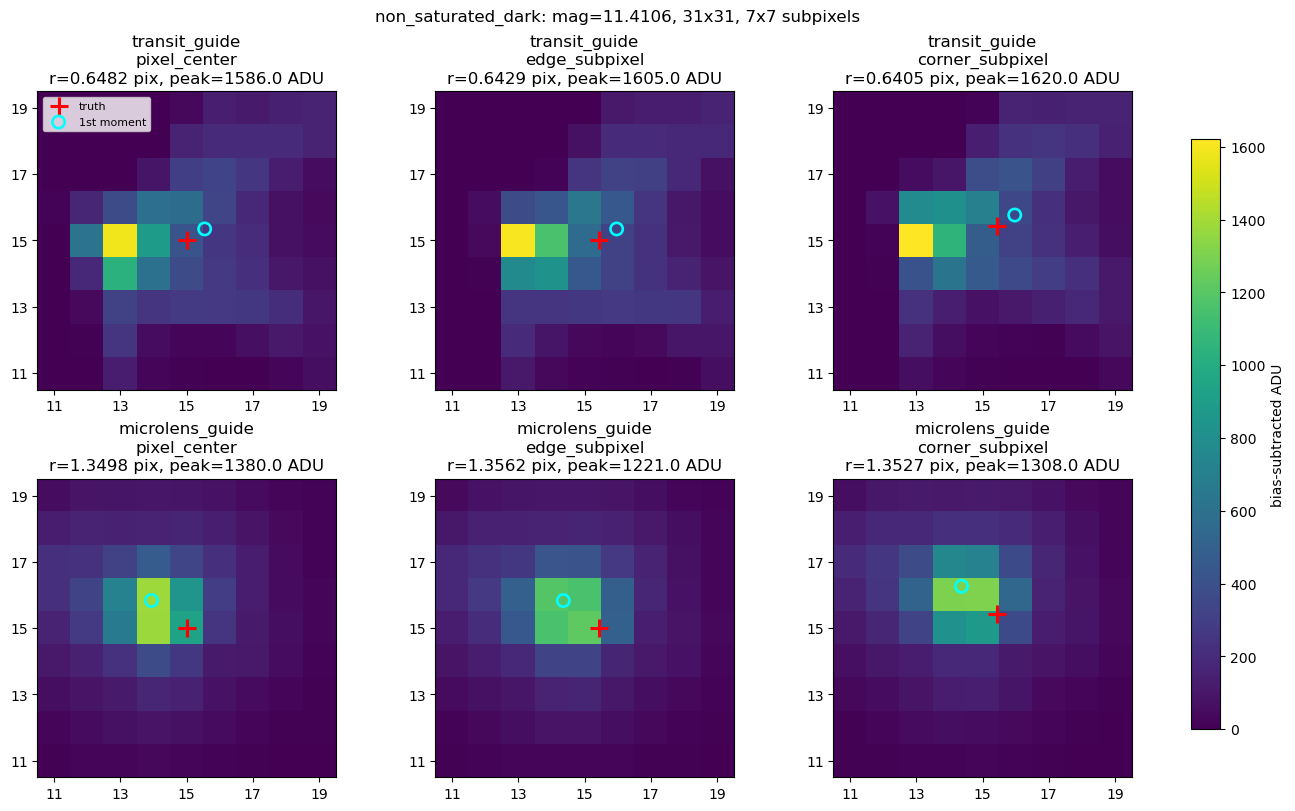

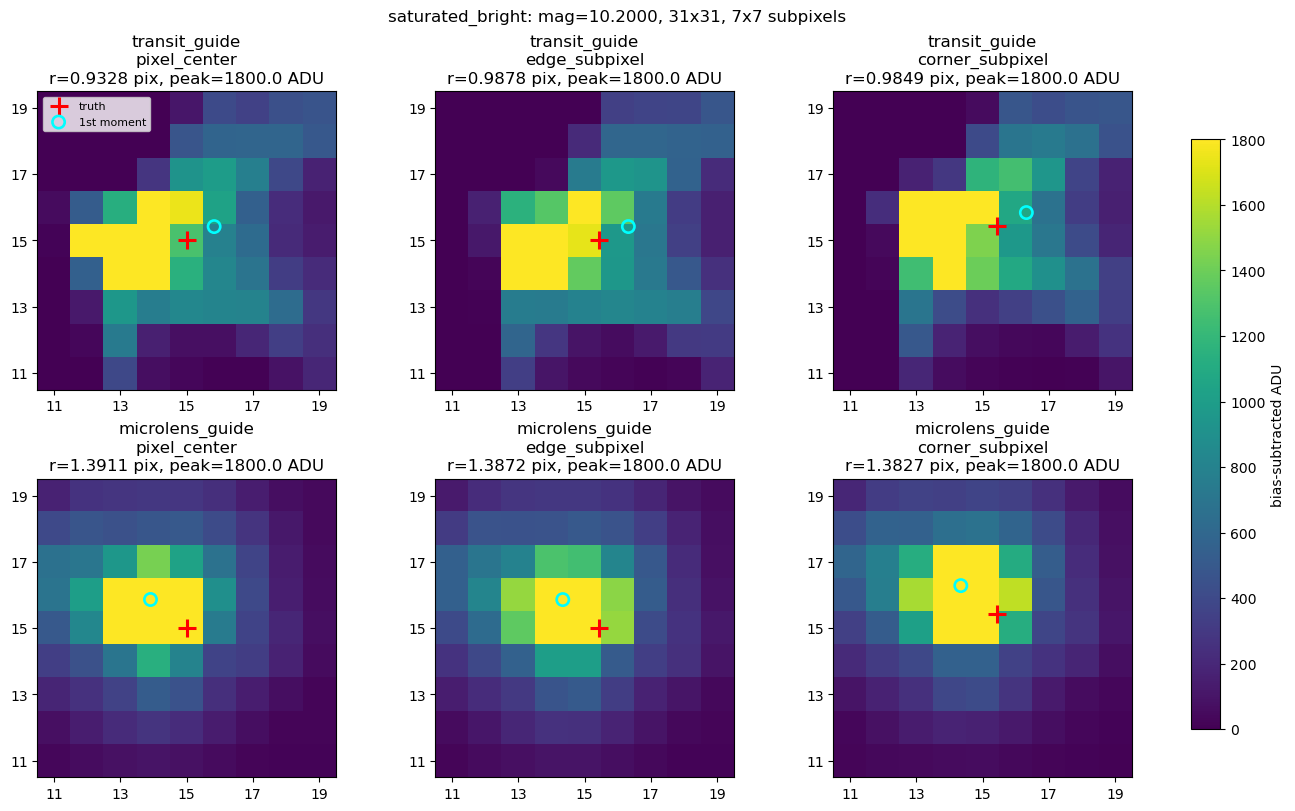

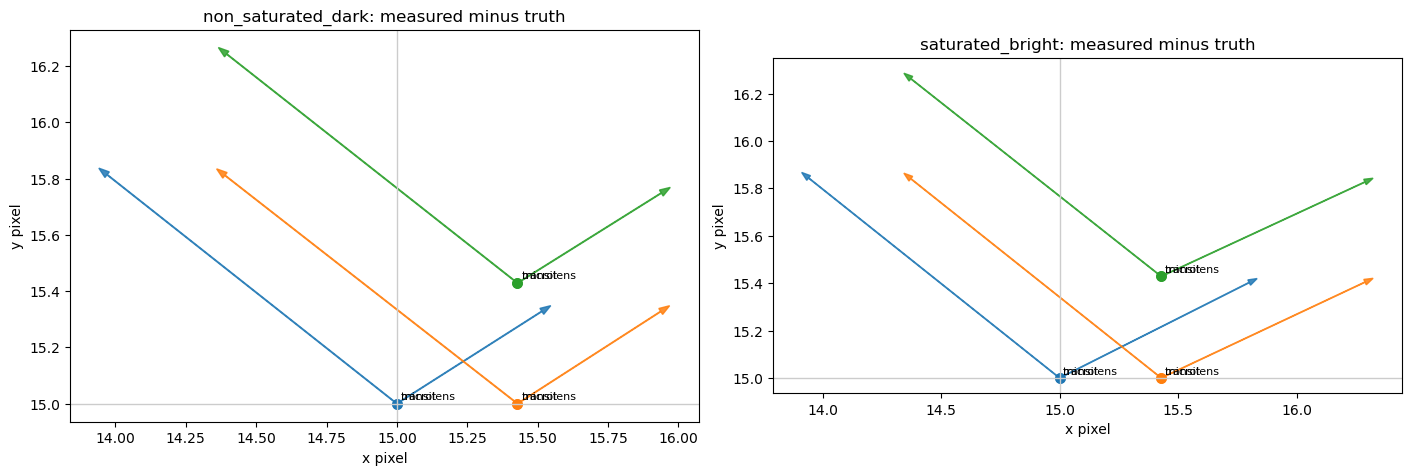

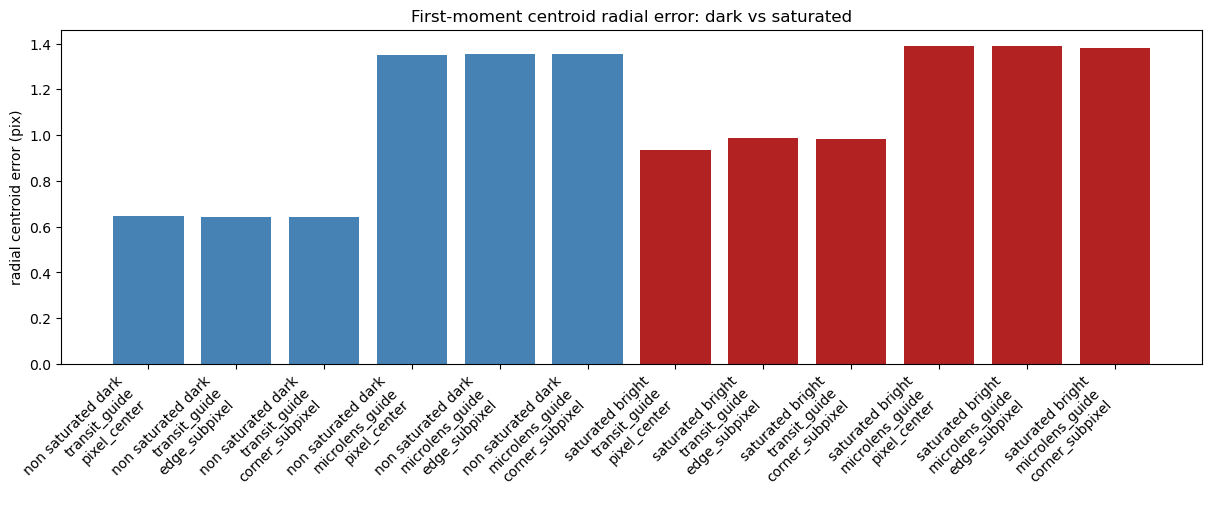

Saved dark stamp overlay: /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp/non_saturated_dark_stamp_truth_vs_measured.png
Saved saturated stamp overlay: /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp/saturated_bright_stamp_truth_vs_measured.png
Saved bias vector plot: /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp/centroid_bias_vectors_dark_vs_saturated.png
Saved radial error plot: /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp/centroid_radial_error_dark_vs_saturated.png


In [14]:
def plot_scenario_stamp_grid(
    analysis_table: pd.DataFrame,
    stamps: dict[str, np.ndarray],
    scenario_name: str,
    out_path: Path,
) -> Path:
    detectors = [spec["detector"] for spec in DETECTOR_SPECS]
    phases = [phase["phase_label"] for phase in PHASES]
    fig, axes = plt.subplots(len(detectors), len(phases), figsize=(13.5, 8.0), constrained_layout=True)

    scenario_rows = analysis_table[analysis_table["scenario"] == scenario_name]
    scenario_stamps = [stamps[row.key] for row in scenario_rows.itertuples(index=False)]
    vmin = 0.0
    vmax = float(max(stamp.max() for stamp in scenario_stamps))
    im = None

    for row_index, detector in enumerate(detectors):
        for col_index, phase_label in enumerate(phases):
            ax = axes[row_index, col_index]
            row = scenario_rows[(scenario_rows["detector"] == detector) & (scenario_rows["phase_label"] == phase_label)].iloc[0]
            stamp = stamps[row["key"]]
            im = ax.imshow(stamp, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax, interpolation="nearest")
            ax.scatter(row["x_true_pix"], row["y_true_pix"], marker="+", s=170, c="red", linewidths=2.2, label="truth")
            ax.scatter(row["x_meas_pix"], row["y_meas_pix"], marker="o", s=78, facecolors="none", edgecolors="cyan", linewidths=1.9, label="1st moment")
            ax.set_title(
                f"{detector}\n{phase_label}\n"
                f"r={row['radial_error_pix']:.4f} pix, peak={row['measured_signal_peak_adu']:.1f} ADU"
            )
            ax.set_xlim(10.5, 19.5)
            ax.set_ylim(10.5, 19.5)
            ax.set_xticks(range(11, 20, 2))
            ax.set_yticks(range(11, 20, 2))
            if row_index == 0 and col_index == 0:
                ax.legend(loc="upper left", fontsize=8)

    assert im is not None
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.86, label="bias-subtracted ADU")
    mag_value = float(scenario_rows["mag_et"].iloc[0])
    fig.suptitle(f"{scenario_name}: mag={mag_value:.4f}, {STAMP_SIZE}x{STAMP_SIZE}, {N_SUBPIXELS}x{N_SUBPIXELS} subpixels")
    fig.savefig(out_path, dpi=180)
    plt.show()
    return out_path


def plot_bias_summary(analysis_table: pd.DataFrame) -> tuple[Path, Path]:
    fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.8), constrained_layout=True)
    colors = {"pixel_center": "tab:blue", "edge_subpixel": "tab:orange", "corner_subpixel": "tab:green"}
    for ax, scenario_name in zip(axes, ["non_saturated_dark", "saturated_bright"]):
        scenario_rows = analysis_table[analysis_table["scenario"] == scenario_name]
        for _, row in scenario_rows.iterrows():
            ax.arrow(
                row["x_true_pix"],
                row["y_true_pix"],
                row["dx_meas_minus_true_pix"],
                row["dy_meas_minus_true_pix"],
                width=0.002,
                head_width=0.025,
                length_includes_head=True,
                color=colors[row["phase_label"]],
                alpha=0.85,
            )
            ax.scatter(row["x_true_pix"], row["y_true_pix"], c=colors[row["phase_label"]], s=45)
            ax.text(row["x_true_pix"] + 0.015, row["y_true_pix"] + 0.015, row["detector"].replace("_guide", ""), fontsize=8)
        ax.axhline(CENTER_PIX, color="0.8", lw=1)
        ax.axvline(CENTER_PIX, color="0.8", lw=1)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x pixel")
        ax.set_ylabel("y pixel")
        ax.set_title(f"{scenario_name}: measured minus truth")
    arrow_path = OUTPUT_DIR / "centroid_bias_vectors_dark_vs_saturated.png"
    fig.savefig(arrow_path, dpi=180)
    plt.show()

    fig, ax = plt.subplots(figsize=(12.0, 5.0), constrained_layout=True)
    labels = analysis_table["scenario"].str.replace("_", " ") + "\n" + analysis_table["detector"] + "\n" + analysis_table["phase_label"]
    bar_colors = ["steelblue" if scenario == "non_saturated_dark" else "firebrick" for scenario in analysis_table["scenario"]]
    ax.bar(np.arange(len(analysis_table)), analysis_table["radial_error_pix"], color=bar_colors)
    ax.set_xticks(np.arange(len(analysis_table)), labels, rotation=45, ha="right")
    ax.set_ylabel("radial centroid error (pix)")
    ax.set_title("First-moment centroid radial error: dark vs saturated")
    bar_path = OUTPUT_DIR / "centroid_radial_error_dark_vs_saturated.png"
    fig.savefig(bar_path, dpi=180)
    plt.show()
    return arrow_path, bar_path


dark_stamp_plot_path = plot_scenario_stamp_grid(
    analysis_table,
    measurement_stamps,
    "non_saturated_dark",
    OUTPUT_DIR / "non_saturated_dark_stamp_truth_vs_measured.png",
)
saturated_stamp_plot_path = plot_scenario_stamp_grid(
    analysis_table,
    measurement_stamps,
    "saturated_bright",
    OUTPUT_DIR / "saturated_bright_stamp_truth_vs_measured.png",
)
vector_plot_path, bar_plot_path = plot_bias_summary(analysis_table)
print(f"Saved dark stamp overlay: {dark_stamp_plot_path}")
print(f"Saved saturated stamp overlay: {saturated_stamp_plot_path}")
print(f"Saved bias vector plot: {vector_plot_path}")
print(f"Saved radial error plot: {bar_plot_path}")

## 7. 保存结果并给出报告用总结

保存内容包括：完整残差CSV、显示用stamp NPZ、原始加偏置ADC图NPZ、暗星/饱和亮星两张2×3叠加图、偏差矢量图、径向误差柱状图，以及一张可视化汇总表。最后打印两种星等、放置位置、测量偏差的摘要。

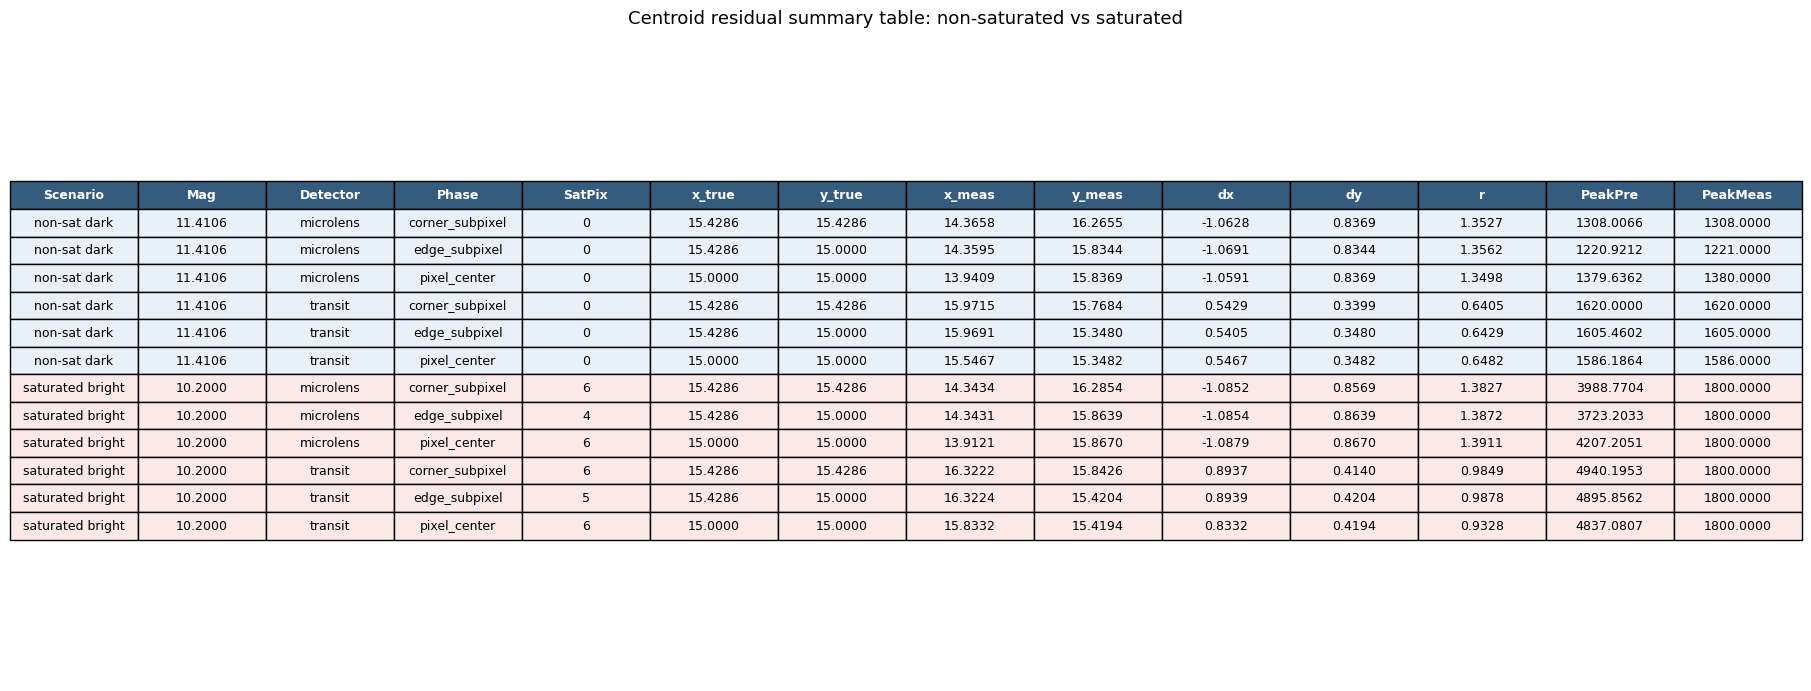

Saved outputs:
  CSV:  /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp/psf_centroid_bias_dark_and_saturated_results.csv
  measurement NPZ: /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp/bias_subtracted_measurement_stamps_31x31.npz
  raw bias+ADC NPZ: /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp/raw_bias_adc_stamps_31x31.npz
  visual table PNG: /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp/centroid_summary_visual_table.png
  JSON: /home/liyang/ET7/Results/psf_centroid_bias_subpixel_stamp/psf_centroid_bias_dark_and_saturated_summary.json

Report-ready centroid residual summary:
  非饱和暗星星等: 11.4106 mag, peak < 1800.0 ADU
  饱和亮星星等: 10.2000 mag, preclip peak > 1800.0 ADU, full-well clipped before bias/ADC
  non_saturated_dark   mag=11.4106 microlens_guide corner_subpixel  truth=(15.428571,15.428571) meas=(14.365814,16.265497) dx=-1.062757, dy=+0.836925, r=1.352737 pix, saturated_pixels=0
  non_saturated_dark   mag=11.4106 microlens_guide edge_sub

,scenario,mag_et,detector,phase_label,n_saturated_pixels,x_true_pix,y_true_pix,x_meas_pix,y_meas_pix,dx_meas_minus_true_pix,dy_meas_minus_true_pix,radial_error_pix,preclip_peak_adu,measured_signal_peak_adu
0,non_saturated_dark,11.410573,microlens_guide,corner_subpixel,0,15.428571,15.428571,14.365814,16.265497,-1.062757,0.836925,1.352737,1308.006604,1308.0
1,non_saturated_dark,11.410573,microlens_guide,edge_subpixel,0,15.428571,15.000000,14.359459,15.834390,-1.069112,0.834390,1.356174,1220.921241,1221.0
2,non_saturated_dark,11.410573,microlens_guide,pixel_center,0,15.000000,15.000000,13.940933,15.836878,-1.059067,0.836878,1.349810,1379.636205,1380.0
3,non_saturated_dark,11.410573,transit_guide,corner_subpixel,0,15.428571,15.428571,15.971458,15.768436,0.542886,0.339865,0.640495,1620.000000,1620.0
4,non_saturated_dark,11.410573,transit_guide,edge_subpixel,0,15.428571,15.000000,15.969114,15.347990,0.540543,0.347990,0.642871,1605.460215,1605.0
5,non_saturated_dark,11.410573,transit_guide,pixel_center,0,15.000000,15.000000,15.546709,15.348226,0.546709,0.348226,0.648191,1586.186417,1586.0
6,saturated_bright,10.200000,microlens_guide,corner_subpixel,6,15.428571,15.428571,14.343384,16.285450,-1.085187,0.856878,1.382705,3988.770416,1800.0
7,saturated_bright,10.200000,microlens_guide,edge_subpixel,4,15.428571,15.000000,14.343139,15.863860,-1.085432,0.863860,1.387233,3723.203317,1800.0
8,saturated_bright,10.200000,microlens_guide,pixel_center,6,15.000000,15.000000,13.912088,15.866956,-1.087912,0.866956,1.391102,4207.205117,1800.0
9,saturated_bright,10.200000,transit_guide,corner_subpixel,6,15.428571,15.428571,16.322230,15.842571,0.893659,0.413999,0.984897,4940.195296,1800.0



结论：无噪声条件下仍存在非零残差，说明残差不是随机噪声造成的。非饱和暗星的残差主要来自PSF形状、亚像素采样/像素积分和31x31窗口截断；饱和亮星额外引入满阱截断，使核心PSF形状被削平，通常会改变一阶矩质心偏差。


In [15]:
csv_path = OUTPUT_DIR / "psf_centroid_bias_dark_and_saturated_results.csv"
summary_json_path = OUTPUT_DIR / "psf_centroid_bias_dark_and_saturated_summary.json"
measurement_npz_path = OUTPUT_DIR / "bias_subtracted_measurement_stamps_31x31.npz"
raw_npz_path = OUTPUT_DIR / "raw_bias_adc_stamps_31x31.npz"
preclip_npz_path = OUTPUT_DIR / "preclip_psf_signal_stamps_31x31.npz"
visual_table_png_path = OUTPUT_DIR / "centroid_summary_visual_table.png"

analysis_table.to_csv(csv_path, index=False)
np.savez_compressed(measurement_npz_path, **measurement_stamps)
np.savez_compressed(raw_npz_path, **raw_stamps)
np.savez_compressed(preclip_npz_path, **preclip_stamps)

summary_table = (
    analysis_table[
        [
            "scenario",
            "mag_et",
            "detector",
            "phase_label",
            "n_saturated_pixels",
            "x_true_pix",
            "y_true_pix",
            "x_meas_pix",
            "y_meas_pix",
            "dx_meas_minus_true_pix",
            "dy_meas_minus_true_pix",
            "radial_error_pix",
            "preclip_peak_adu",
            "measured_signal_peak_adu",
        ]
    ]
    .sort_values(["scenario", "detector", "phase_label"])
    .reset_index(drop=True)
)

summary_display_table = summary_table.copy()
summary_display_table["scenario"] = summary_display_table["scenario"].map(
    {
        "non_saturated_dark": "non-sat dark",
        "saturated_bright": "saturated bright",
    }
)
summary_display_table["detector"] = summary_display_table["detector"].map(
    {
        "transit_guide": "transit",
        "microlens_guide": "microlens",
    }
)
for col in [
    "mag_et",
    "x_true_pix",
    "y_true_pix",
    "x_meas_pix",
    "y_meas_pix",
    "dx_meas_minus_true_pix",
    "dy_meas_minus_true_pix",
    "radial_error_pix",
    "preclip_peak_adu",
    "measured_signal_peak_adu",
]:
    summary_display_table[col] = summary_display_table[col].map(lambda value: f"{float(value):.4f}")
summary_display_table["n_saturated_pixels"] = summary_display_table["n_saturated_pixels"].astype(int)
summary_display_table = summary_display_table.rename(
    columns={
        "scenario": "Scenario",
        "mag_et": "Mag",
        "detector": "Detector",
        "phase_label": "Phase",
        "n_saturated_pixels": "SatPix",
        "x_true_pix": "x_true",
        "y_true_pix": "y_true",
        "x_meas_pix": "x_meas",
        "y_meas_pix": "y_meas",
        "dx_meas_minus_true_pix": "dx",
        "dy_meas_minus_true_pix": "dy",
        "radial_error_pix": "r",
        "preclip_peak_adu": "PeakPre",
        "measured_signal_peak_adu": "PeakMeas",
    }
)

fig_height = 0.45 * len(summary_display_table) + 1.4
fig, ax = plt.subplots(figsize=(18.0, fig_height), constrained_layout=True)
ax.axis("off")
visual_table = ax.table(
    cellText=summary_display_table.values,
    colLabels=summary_display_table.columns,
    cellLoc="center",
    loc="center",
)
visual_table.auto_set_font_size(False)
visual_table.set_fontsize(9)
visual_table.scale(1.0, 1.35)
for (row_idx, col_idx), cell in visual_table.get_celld().items():
    if row_idx == 0:
        cell.set_text_props(weight="bold", color="white")
        cell.set_facecolor("#355C7D")
    else:
        scenario_name = summary_display_table.iloc[row_idx - 1]["Scenario"]
        cell.set_facecolor("#E8F1F8" if scenario_name == "non-sat dark" else "#FBE9E7")
ax.set_title("Centroid residual summary table: non-saturated vs saturated", fontsize=13, pad=12)
fig.savefig(visual_table_png_path, dpi=180, bbox_inches="tight")
plt.show()

mean_radial_error_by_scenario_detector = {
    f"{scenario}__{detector}": float(value)
    for (scenario, detector), value in analysis_table.groupby(["scenario", "detector"])["radial_error_pix"].mean().items()
}

summary = {
    "requested_reference_mag_et": STAR_MAG_ET,
    "dark_non_saturated_mag_et": float(dark_mag_et),
    "bright_saturated_mag_et": float(bright_mag_et),
    "exposure_s": GUIDE_EXPOSURE_S,
    "stamp_size": STAMP_SIZE,
    "n_subpixels": N_SUBPIXELS,
    "full_well_adu": SATURATION_LIMIT_ADU,
    "bias_adu": BIAS_ADU,
    "adc_bit_depth": ADC_BIT_DEPTH,
    "adc_max_adu": ADC_MAX_ADU,
    "max_radial_error_pix": float(analysis_table["radial_error_pix"].max()),
    "mean_radial_error_by_scenario_detector_pix": mean_radial_error_by_scenario_detector,
    "outputs": {
        "csv": str(csv_path),
        "measurement_npz": str(measurement_npz_path),
        "raw_npz": str(raw_npz_path),
        "preclip_npz": str(preclip_npz_path),
        "dark_stamp_overlay_png": str(dark_stamp_plot_path),
        "saturated_stamp_overlay_png": str(saturated_stamp_plot_path),
        "bias_vector_png": str(vector_plot_path),
        "radial_error_png": str(bar_plot_path),
        "visual_table_png": str(visual_table_png_path),
    },
}
summary_json_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved outputs:")
print(f"  CSV:  {csv_path}")
print(f"  measurement NPZ: {measurement_npz_path}")
print(f"  raw bias+ADC NPZ: {raw_npz_path}")
print(f"  visual table PNG: {visual_table_png_path}")
print(f"  JSON: {summary_json_path}")

print("\nReport-ready centroid residual summary:")
print(f"  非饱和暗星星等: {dark_mag_et:.4f} mag, peak < {SATURATION_LIMIT_ADU:.1f} ADU")
print(f"  饱和亮星星等: {bright_mag_et:.4f} mag, preclip peak > {SATURATION_LIMIT_ADU:.1f} ADU, full-well clipped before bias/ADC")
for row in summary_table.itertuples(index=False):
    print(
        f"  {row.scenario:20s} mag={row.mag_et:.4f} {row.detector:15s} {row.phase_label:16s} "
        f"truth=({row.x_true_pix:.6f},{row.y_true_pix:.6f}) "
        f"meas=({row.x_meas_pix:.6f},{row.y_meas_pix:.6f}) "
        f"dx={row.dx_meas_minus_true_pix:+.6f}, dy={row.dy_meas_minus_true_pix:+.6f}, "
        f"r={row.radial_error_pix:.6f} pix, saturated_pixels={row.n_saturated_pixels}"
    )

print("\nTable for report display:")
display(summary_table)
print(
    "\n结论：无噪声条件下仍存在非零残差，说明残差不是随机噪声造成的。"
    "非饱和暗星的残差主要来自PSF形状、亚像素采样/像素积分和31x31窗口截断；"
    "饱和亮星额外引入满阱截断，使核心PSF形状被削平，通常会改变一阶矩质心偏差。"
)

## 8. 报告用结论

本实验在无噪声条件下，仅保留PSF、像素积分、31×31窗口截断以及饱和模型本身的影响，对凌星导星探测器与微引力导星探测器分别在三个亚像素相位位置进行了质心测试。结果表明，即使没有任何随机噪声，一阶灰度加权质心相对真值质心仍存在稳定的系统偏差，因此该偏差不是噪声项造成，而是由PSF形状、像素积分、亚像素采样相位和窗口截断共同决定。

本次用于报告的两种星等分别为：

- 非饱和暗星：11.4106等，保证最亮像素低于1800 ADU。
- 饱和亮星：10.2000等，在无噪声条件下其最亮像素显著超过1800 ADU，并按满阱1800 ADU、偏置135 ADU、12bit ADC做截断与量化。

三个放置位置分别为：

- 像素中心：$(15.000000, 15.000000)$
- 边亚像素点：$(15.428571, 15.000000)$
- 角亚像素点：$(15.428571, 15.428571)$

主要结果如下：

- 凌星导星探测器在非饱和暗星条件下的径向偏差约为0.640至0.648 pixel；10.2等饱和亮星下会有更多饱和像素，且一阶矩质心相对非饱和情况继续偏离。
- 微引力导星探测器在非饱和暗星条件下的径向偏差约为1.350至1.356 pixel；10.2等饱和亮星下同样可稳定进入饱和，并保持明显系统偏差。
- 同一探测器在三个亚像素相位上的偏差略有变化，说明偏差不仅与PSF本身形状有关，也与星点中心相对于像素网格的落点有关。
- 两类探测器偏差方向和幅值不同，说明不同PSF形状及其不对称性是造成系统偏差的重要来源。

因此，可以将本实验结论概括为：一阶灰度加权质心对PSF形状和采样相位高度敏感；在无噪声情况下仍然存在明显系统误差，而更亮、更真实的10.2等饱和星会进一步改变核心光斑形状并放大部分探测器的质心偏差。